# Drone detection and tracking demo

How the **v0.883 boosted pipeline** works, how it scores on the original
practice data and on native 1080p DUT footage, and what those results look
like in seven annotated videos.

The saved previews play inside the notebook. Each dataset section also links
to its full-length annotated MP4s. Use the **Python (Drone Tracking v2)** kernel
to recompute the score tables from the archived tracker outputs.

In [1]:
import json
import sys
from io import BytesIO
from pathlib import Path
from urllib.parse import quote

import cv2
import matplotlib.pyplot as plt
import motmetrics as mm
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, Video, display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / "pipeline_boost.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open the notebook from the Drone Tracking v2 workspace.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from eval_track import load_ids, mot

PRACTICE_RUN = ROOT / "preds" / "experiments" / "20261121-101320-d88v4swu"
DUT_RUN = ROOT / "preds" / "dut_evaluation" / "notebook-rerun-qb_ys_fn"
DUT_DATA = ROOT / "drone_data" / "dut_1080p_test"
MEDIA = ROOT / "demo_out" / "pipeline_demo"
PRESETS = ("tracker-only", "trajectory", "v0.883-boosted")
BOOSTED = "v0.883-boosted"
LABELS = {"practice": "Original practice", "dut": "DUT 1080p"}

## 1. Architecture

The full-frame detector supplies initial boxes for each RGB frame. The
tracker's state from previous frames guides a second look at locations where
an existing target may have been missed. The v0.883 checkpoint examines those
crops before the pipeline adjusts candidate scores and updates the tracks.

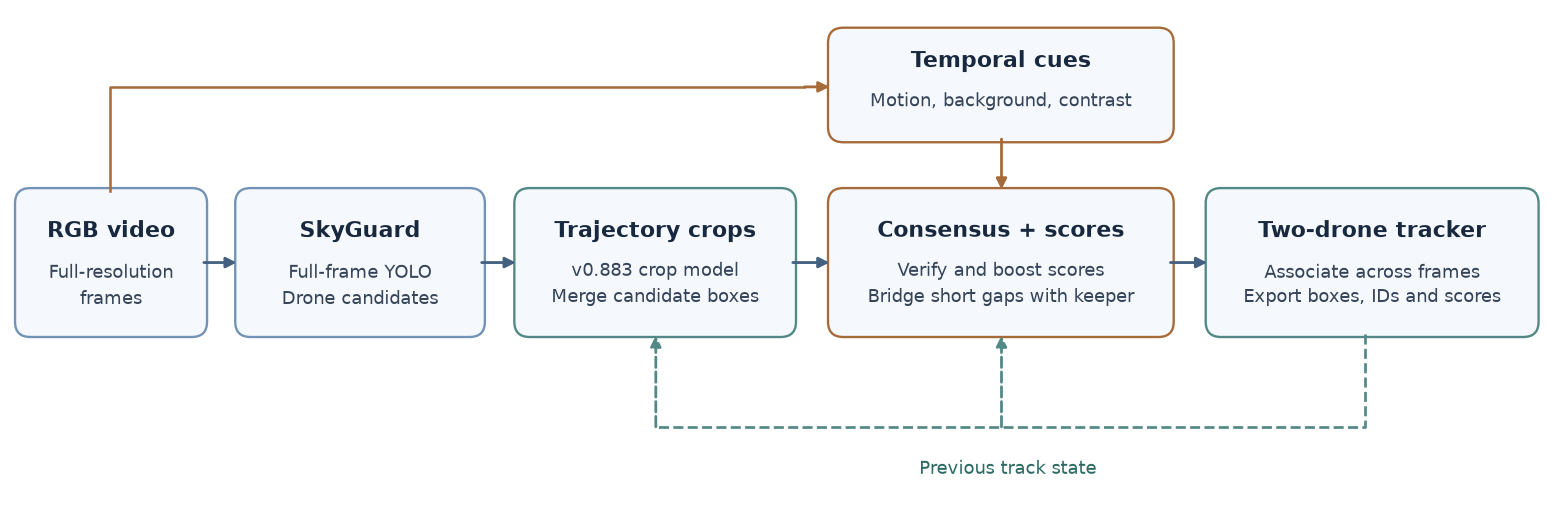

In [2]:
def render_diagram():
    fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
    ax.set(xlim=(0, 12.1), ylim=(0, 4))
    ax.set_axis_off()

    def box(x, y, w, h, title, body, accent):
        ax.add_patch(FancyBboxPatch(
            (x, y), w, h, boxstyle="round,pad=0.025,rounding_size=0.12",
            linewidth=1.3, edgecolor=accent, facecolor="#f5f8fc",
        ))
        ax.text(x + w / 2, y + h * 0.72, title, ha="center", va="center",
                fontsize=12, color="#17283f", fontweight=700)
        ax.text(x + w / 2, y + h * 0.35, body, ha="center", va="center",
                fontsize=10, color="#36455a", linespacing=1.45)

    def arrow(start, end, *, accent="#436080", linestyle="-"):
        ax.add_patch(FancyArrowPatch(
            start, end, arrowstyle="-|>", linewidth=1.55, mutation_scale=12,
            color=accent, linestyle=linestyle, shrinkA=0, shrinkB=1,
        ))

    box(0.10, 1.42, 1.45, 1.12, "RGB video", "Full-resolution\nframes", "#7293b6")
    box(1.82, 1.42, 1.90, 1.12, "SkyGuard", "Full-frame YOLO\nDrone candidates", "#7293b6")
    box(4.00, 1.42, 2.15, 1.12, "Trajectory crops", "v0.883 crop model\nMerge candidate boxes", "#528986")
    box(6.45, 1.42, 2.65, 1.12, "Consensus + scores", "Verify and boost scores\nBridge short gaps with keeper", "#a76b39")
    box(9.40, 1.42, 2.55, 1.12, "Two-drone tracker", "Associate across frames\nExport boxes, IDs and scores", "#528986")
    box(6.45, 2.95, 2.65, 0.85, "Temporal cues", "Motion, background, contrast", "#a76b39")

    for start, end in ((1.55, 1.82), (3.72, 4.00), (6.15, 6.45), (9.10, 9.40)):
        arrow((start, 1.98), (end, 1.98))
    ax.plot([0.82, 0.82, 6.24], [2.54, 3.36, 3.36], color="#a76b39", lw=1.4)
    arrow((6.24, 3.36), (6.45, 3.36), accent="#a76b39")
    arrow((7.78, 2.95), (7.78, 2.54), accent="#a76b39")

    feedback = "#528986"
    ax.plot([10.62, 10.62, 5.08], [1.42, 0.69, 0.69], lw=1.5, color=feedback, ls="--")
    arrow((5.08, 0.69), (5.08, 1.42), accent=feedback, linestyle="--")
    arrow((7.78, 0.69), (7.78, 1.42), accent=feedback, linestyle="--")
    ax.text(7.83, 0.32, "Previous track state", ha="center", fontsize=10, color="#2e6b65")

    with BytesIO() as png:
        fig.savefig(png, format="png", dpi=130, facecolor="white")
        display(Image(data=png.getvalue(), format="png"))
    plt.close(fig)


render_diagram()

| Stage | What the demo preset does |
|---|---|
| Full-frame detection | Runs SkyGuard at 1280 px and retains drone candidates scoring at least 0.01. |
| Trajectory-guided search | Checks a 320 px crop around a predicted track when the full-frame detections provide too little support. Enlarges the crop 2×, applies the v0.883 checkpoint and merges the boxes. |
| Temporal consensus | Builds motion, background and contrast cues at 480 px. The verifier reduces weak unsupported scores. The boost raises qualifying scores in [0.10, 0.30) to 0.65. |
| Track keeper and association | The motion-aware keeper can bridge a short gap of up to five frames. A Kalman tracker updates box positions and assigns up to two IDs. |

The demo uses the recorded-video preset. Standalone motion-seeded crops
are off. Motion still contributes to consensus and the track keeper.
[Pipeline source](../pipeline_boost.py) · [Tracker source](../tracker.py)

## 2. Test results

Both datasets use IoU ≥ 0.50. Recall counts how many labeled drone boxes the
tracker matched, and precision counts the fraction of output boxes that
matched. MOTA includes misses, false positives and ID switches. IDF1 measures
how consistently predicted and reference identities align.

The original practice set has three clips and allows two labeled drones.
The DUT sample has four single-drone clips and keeps the source 1920 × 1080
resolution. Its frame order comes from the authors' JPEG sequence and its
MP4 playback uses 30 fps. The practice clips are the project benchmark.
DUT is a separate public benchmark, with unknown prior exposure in the SkyGuard
training set. [DUT authors' dataset](https://github.com/wangdongdut/DUT-Anti-UAV)

In [3]:
practice_info = json.loads((PRACTICE_RUN / "settings.json").read_text(encoding="utf-8"))
dut_info = json.loads((DUT_RUN / "benchmark.json").read_text(encoding="utf-8"))
groups = {
    "practice": [(item["name"], Path(item["video"]), Path(item["ground_truth"]))
                 for item in practice_info["clips"]],
    "dut": [(item["clip"], DUT_DATA / item["clip"] / "video.mp4",
             DUT_DATA / item["clip"] / "gt" / "gt.txt") for item in dut_info["clips"]],
}

def read_labels(path, with_scores=False):
    if not path.is_file():
        raise FileNotFoundError(path)
    return load_ids(path, with_scores)

def track_dir(group, preset):
    return (PRACTICE_RUN / "configs" / preset / "tracks" if group == "practice"
            else DUT_RUN / f"tracks-{preset}")

clips = []
truth = {}
for group, items in groups.items():
    for name, source, ground_truth in items:
        labels = read_labels(ground_truth)
        annotated = MEDIA / group / f"{name}.mp4"
        if not annotated.is_file():
            raise FileNotFoundError(annotated)
        video = cv2.VideoCapture(str(source))
        try:
            count = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = video.get(cv2.CAP_PROP_FPS)
        finally:
            video.release()
        if count <= 0 or fps <= 0:
            raise RuntimeError(f"Could not read the video metadata for {source}.")
        short = name.rsplit("_", 1)[-1].title() if group == "practice" else f"DUT {name[-2:]}"
        clips.append({
            "group": group, "clip": name, "label": short, "frames": count, "seconds": count / fps,
            "gt_boxes": sum(map(len, labels.values())), "video": annotated,
        })
        truth[name] = labels
clip_info = pd.DataFrame(clips).set_index("clip")

coverage = clip_info.groupby("group", sort=False).agg(
    Clips=("label", "size"), Frames=("frames", "sum"), Seconds=("seconds", "sum"),
    Labeled_boxes=("gt_boxes", "sum"),
).rename(index=LABELS, columns={"Labeled_boxes": "Labeled boxes"})
display(coverage.style.format({
    "Frames": "{:,.0f}", "Seconds": "{:.1f}", "Labeled boxes": "{:,.0f}",
}))

,Clips,Frames,Seconds,Labeled boxes
group,,,,
Original practice,3,"2,599",86.6,"3,595"
DUT 1080p,4,"1,491",49.7,"1,452"


In [4]:
metrics = ["mota", "idf1", "precision", "recall", "num_switches", "num_false_positives", "num_misses"]
scorer = mm.metrics.create()
tables = {}
for group, items in groups.items():
    names = [name for name, *_ in items]
    saved = (pd.read_csv(PRACTICE_RUN / "mot_metrics.csv") if group == "practice" else pd.concat([
        pd.read_csv(DUT_RUN / "mot_by_clip.csv"),
        pd.read_csv(DUT_RUN / "mot_overview.csv").query("lighting == 'overall'").assign(clip="OVERALL"),
    ], ignore_index=True))
    for preset in PRESETS:
        predictions = [read_labels(track_dir(group, preset) / f"{name}.txt", True) for name in names]
        accumulators = [mot(truth[name], pred, 0.0) for name, pred in zip(names, predictions, strict=True)]
        measured = scorer.compute_many(
            accumulators, names=names, generate_overall=True, metrics=metrics,
        )
        expected = saved.loc[saved["experiment"].eq(preset)].set_index("clip").loc[measured.index, metrics]
        np.testing.assert_allclose(measured[metrics], expected, rtol=1e-7, atol=1e-9, equal_nan=True)
        tables[(group, preset)] = measured
scores = pd.concat(tables, names=["group", "preset", "clip"])

def format_scores(table):
    return table.rename(columns={
        "mota": "MOTA", "idf1": "IDF1", "precision": "Precision", "recall": "Recall",
        "num_switches": "ID switches", "num_false_positives": "False positives",
        "num_misses": "Misses",
    }).style.format({
        "MOTA": "{:.3f}", "IDF1": "{:.3f}", "Precision": "{:.2%}", "Recall": "{:.2%}",
        "ID switches": "{:,.0f}", "False positives": "{:,.0f}", "Misses": "{:,.0f}",
    }, na_rep="—")

pooled = scores.xs("OVERALL", level="clip").rename(index=LABELS, level="group")
display(format_scores(pooled))

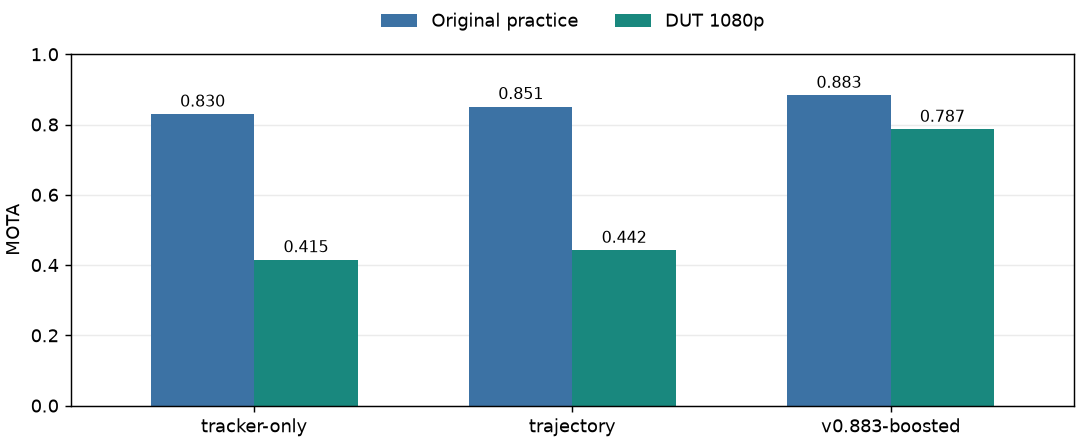

In [5]:
fig, ax = plt.subplots(figsize=(8.3, 3.4), layout="constrained")
ablation = pooled["mota"].unstack("group").reindex(index=PRESETS, columns=list(LABELS.values()))
ablation.plot.bar(ax=ax, color=["#3c72a4", "#19887e"], width=0.65, rot=0)
ax.set(xlabel=None, ylabel="MOTA", ylim=(0, 1))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title=None, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncols=2, frameon=False)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9)
with BytesIO() as png:
    fig.savefig(png, format="png", dpi=130, facecolor="white")
    display(Image(data=png.getvalue(), format="png"))
plt.close(fig)

## 3. Annotated playback

**Cyan** marks reference boxes and IDs. **Orange** marks the boosted track
boxes, IDs and confidence scores. IDs are assigned independently by the
tracker. The metrics above match boxes by overlap and evaluate identity over
time. The full-length videos use the saved predictions and retain every
evaluated frame. Playback is silent.

In [6]:
PLAY_FULL = {"practice": None, "dut": None}
# To embed a full clip in this cell's output, set e.g. {"practice": "Hard", "dut": "DUT 18"}.
# The default embeds two short highlights and links every full-length MP4.

HIGHLIGHTS = {
    "practice": ("practice-easy.mp4", "Original practice · Easy · 8–14 seconds"),
    "dut": ("dut-video18.mp4", "DUT 18 · 3.5–9.5 seconds · extra tracks appear around clutter"),
}

def video_href(path):
    return "../" + quote(path.relative_to(ROOT).as_posix(), safe="/")

def show_clips(group):
    entries = clip_info.loc[clip_info["group"].eq(group)]
    per_clip = scores.xs((group, BOOSTED), level=("group", "preset")).drop(index="OVERALL")
    display(format_scores(per_clip.rename(index=entries["label"]).rename_axis("Clip")))
    full_videos = [
        f"- [{row.label} · {row.seconds:.1f} s]({video_href(row.video)})"
        f" · {row.frames:,} frames"
        for row in entries.itertuples()
    ]
    display(Markdown("**Full-length annotated videos**\n\n" + "\n".join(full_videos)))

    selected = PLAY_FULL[group]
    if selected is None:
        filename, caption = HIGHLIGHTS[group]
        path = MEDIA / "highlights" / filename
    else:
        choices = entries.set_index("label")
        if selected not in choices.index:
            raise ValueError(f"Choose a clip from {choices.index.tolist()}.")
        path, caption = choices.at[selected, "video"], selected
    display(Markdown(f"**{caption}**"))
    display(Video(filename=str(path), embed=True, mimetype="video/mp4", width=850,
                  html_attributes='controls playsinline preload="metadata"'))

### Original practice clips

The easy highlight shows the tracker following two drones. The hard clip
includes a sustained miss segment around 23–27 seconds.

In [7]:
show_clips("practice")

,MOTA,IDF1,Precision,Recall,ID switches,False positives,Misses
Clip,,,,,,,
Easy,0.964,0.982,99.37%,97.06%,0,5,24
Medium,0.973,0.986,99.74%,97.55%,0,2,19
Hard,0.816,0.900,98.06%,83.20%,0,33,337


**Full-length annotated videos**

- [Easy · 17.0 s](../demo_out/pipeline_demo/practice/final_test_sample_2_PXL_20261113_155046638_easy.mp4) · 511 frames
- [Medium · 23.8 s](../demo_out/pipeline_demo/practice/final_test_sample_PXL_20261113_155046638_medium.mp4) · 713 frames
- [Hard · 45.8 s](../demo_out/pipeline_demo/practice/test_6_hard_PXL_20261113_154422245_hard.mp4) · 1,375 frames

**Original practice · Easy · 8–14 seconds**

### Native 1080p DUT clips

DUT 06 matches all 200 frames. DUT 18 is a useful failure example because
it contributes 181 of the 222 false-positive boxes on this sample.

In [8]:
show_clips("dut")

,MOTA,IDF1,Precision,Recall,ID switches,False positives,Misses
Clip,,,,,,,
DUT 04,0.883,0.936,93.66%,95.31%,2,22,16
DUT 06,1.000,1.000,100.00%,100.00%,0,0,0
DUT 14,0.873,0.934,96.56%,90.51%,0,19,56
DUT 18,0.393,0.759,62.91%,95.64%,0,181,14


**Full-length annotated videos**

- [DUT 04 · 11.4 s](../demo_out/pipeline_demo/dut/dut-video04.mp4) · 341 frames
- [DUT 06 · 6.7 s](../demo_out/pipeline_demo/dut/dut-video06.mp4) · 200 frames
- [DUT 14 · 19.7 s](../demo_out/pipeline_demo/dut/dut-video14.mp4) · 590 frames
- [DUT 18 · 12.0 s](../demo_out/pipeline_demo/dut/dut-video18.mp4) · 360 frames

**DUT 18 · 3.5–9.5 seconds · extra tracks appear around clutter**

## Run inference again

Use the [pipeline experiments notebook](pipeline_experiments.ipynb) to run
fresh inference. Its default dataset points to the original practice clips.
For the DUT sample, set `VIDEO_SOURCE = ROOT / "drone_data" / "dut_1080p_test"`.
This demo recomputes scores and plays annotations from the saved runs.